# Day 1: Images as Data and the Convolution Operation
**Deep Learning Internship, Phase 2 (CNNs)**

Goals: (1) treat an image as a grid of numbers, (2) write 2D convolution by hand in NumPy, (3) apply edge and blur filters, (4) verify the output-size formula, (5) compare parameter counts of conv vs fully connected layers.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=2, suppress=True)

## 1. An image is a grid of numbers
A grayscale image is an `H x W` array (0 = black, 1 = white). A colour image is `3 x H x W` (R, G, B channels).
We build a small 28x28 test image with a square, a circle and a diagonal line, so edges are easy to see.

shape: (28, 28) | min: 0.0 | max: 1.0
[[0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0.]
 [0. 0. 1. 1. 1. 1.]
 [0. 0. 1. 1. 1. 1.]
 [0. 0. 1. 1. 1. 1.]
 [0. 0. 1. 1. 1. 1.]]


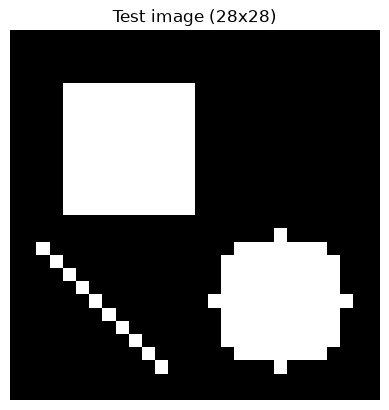

colour image shape (C, H, W): (3, 28, 28)


In [2]:
img = np.zeros((28, 28))
img[4:14, 4:14] = 1.0                         # square
yy, xx = np.ogrid[:28, :28]
img[(yy - 20) ** 2 + (xx - 20) ** 2 <= 25] = 1.0   # circle
for k in range(10):                           # diagonal line
    img[16 + k, 2 + k] = 1.0

print("shape:", img.shape, "| min:", img.min(), "| max:", img.max())
print(img[2:8, 2:8])

plt.imshow(img, cmap="gray")
plt.title("Test image (28x28)")
plt.axis("off")
plt.show()

rgb = np.random.rand(3, 28, 28)
print("colour image shape (C, H, W):", rgb.shape)

## 2. 2D convolution by hand
Slide an `f x f` kernel over the image. At each position, multiply element-wise and sum. The result is one number in the **feature map**.
(Deep learning libraries actually compute cross-correlation, which is what we implement here; the kernel is not flipped.)

In [3]:
def conv2d(image, kernel, stride=1, padding=0):
    if padding > 0:
        image = np.pad(image, padding, mode="constant", constant_values=0)
    H, W = image.shape
    f = kernel.shape[0]
    out_h = (H - f) // stride + 1
    out_w = (W - f) // stride + 1
    out = np.zeros((out_h, out_w))
    for i in range(out_h):
        for j in range(out_w):
            region = image[i * stride:i * stride + f, j * stride:j * stride + f]
            out[i, j] = np.sum(region * kernel)
    return out

# quick sanity check on a tiny example
x = np.arange(16).reshape(4, 4).astype(float)
k = np.ones((2, 2))
print(x)
print(conv2d(x, k))   # each value = sum of a 2x2 block

[[ 0.  1.  2.  3.]
 [ 4.  5.  6.  7.]
 [ 8.  9. 10. 11.]
 [12. 13. 14. 15.]]
[[10. 14. 18.]
 [26. 30. 34.]
 [42. 46. 50.]]


## 3. Edge detection and blur filters

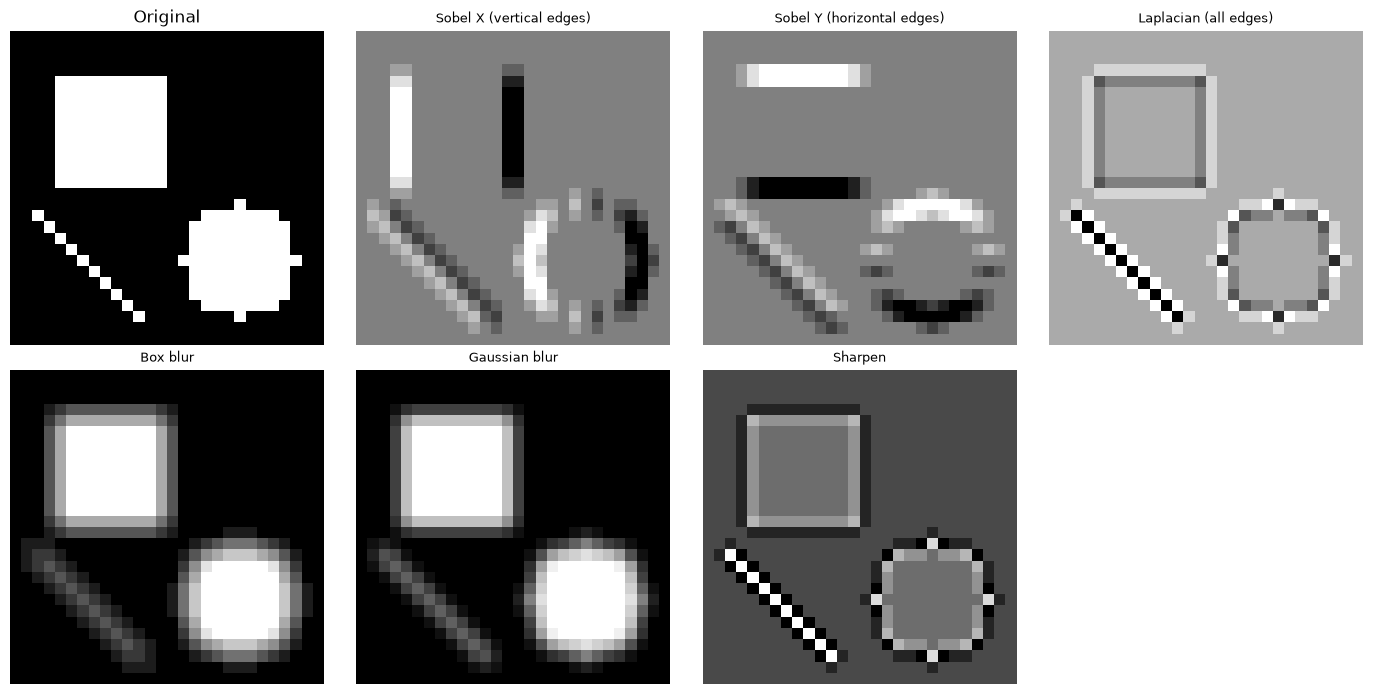

In [4]:
filters = {
    "Sobel X (vertical edges)":   np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], dtype=float),
    "Sobel Y (horizontal edges)": np.array([[-1, -2, -1], [0, 0, 0], [1, 2, 1]], dtype=float),
    "Laplacian (all edges)":      np.array([[0, 1, 0], [1, -4, 1], [0, 1, 0]], dtype=float),
    "Box blur":                   np.ones((3, 3)) / 9.0,
    "Gaussian blur":              np.array([[1, 2, 1], [2, 4, 2], [1, 2, 1]], dtype=float) / 16.0,
    "Sharpen":                    np.array([[0, -1, 0], [-1, 5, -1], [0, -1, 0]], dtype=float),
}

fig, axes = plt.subplots(2, 4, figsize=(14, 7))
axes = axes.ravel()
axes[0].imshow(img, cmap="gray"); axes[0].set_title("Original")
for ax, (name, k) in zip(axes[1:], filters.items()):
    fmap = conv2d(img, k, stride=1, padding=1)
    ax.imshow(fmap, cmap="gray")
    ax.set_title(name, fontsize=9)
axes[7].axis("off")
for ax in axes[:7]:
    ax.axis("off")
plt.tight_layout()
plt.show()

**Observation (write in your own words):** Sobel X lights up vertical edges, Sobel Y horizontal edges, the Laplacian all edges, and the blurs smooth the image. A CNN does not use hand-made filters like these. It *learns* the kernel values during training.

## 4. Padding, stride and the output-size formula
`output = floor((n + 2p - f) / s) + 1`  where n = input size, f = filter size, p = padding, s = stride.

In [5]:
def out_size(n, f, p=0, s=1):
    return (n + 2 * p - f) // s + 1

print(f"{'n':>3} {'f':>3} {'p':>3} {'s':>3} | {'formula':>8} {'actual':>8}")
for f in (3, 5):
    for p in (0, 1, 2):
        for s in (1, 2):
            formula = out_size(28, f, p, s)
            actual = conv2d(img, np.ones((f, f)), stride=s, padding=p).shape[0]
            assert formula == actual, "formula mismatch!"
            print(f"{28:>3} {f:>3} {p:>3} {s:>3} | {formula:>8} {actual:>8}")
print("\nFormula verified for all combinations.")
print("'Same' padding for a 3x3 kernel, stride 1 -> p = 1 keeps size:", out_size(28, 3, 1, 1))

  n   f   p   s |  formula   actual
 28   3   0   1 |       26       26
 28   3   0   2 |       13       13
 28   3   1   1 |       28       28
 28   3   1   2 |       14       14
 28   3   2   1 |       30       30
 28   3   2   2 |       15       15
 28   5   0   1 |       24       24
 28   5   0   2 |       12       12
 28   5   1   1 |       26       26
 28   5   1   2 |       13       13
 28   5   2   1 |       28       28
 28   5   2   2 |       14       14

Formula verified for all combinations.
'Same' padding for a 3x3 kernel, stride 1 -> p = 1 keeps size: 28


## 5. Max pooling
Takes the maximum in each window. It shrinks the map and keeps the strongest response.

before pooling: (28, 28) -> after 2x2 pooling: (14, 14)


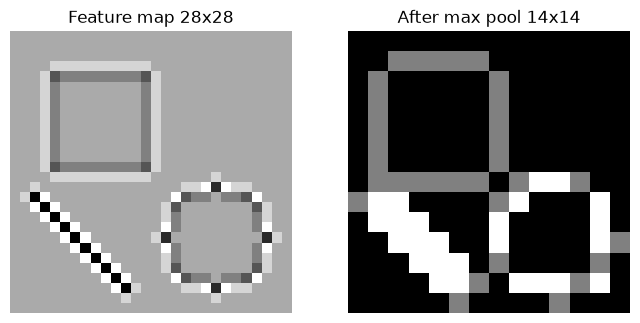

In [6]:
def max_pool2d(fmap, size=2, stride=2):
    H, W = fmap.shape
    out_h = (H - size) // stride + 1
    out_w = (W - size) // stride + 1
    out = np.zeros((out_h, out_w))
    for i in range(out_h):
        for j in range(out_w):
            out[i, j] = fmap[i * stride:i * stride + size, j * stride:j * stride + size].max()
    return out

edges = conv2d(img, filters["Laplacian (all edges)"], padding=1)
pooled = max_pool2d(edges)
print("before pooling:", edges.shape, "-> after 2x2 pooling:", pooled.shape)

fig, ax = plt.subplots(1, 2, figsize=(8, 4))
ax[0].imshow(edges, cmap="gray"); ax[0].set_title("Feature map 28x28")
ax[1].imshow(pooled, cmap="gray"); ax[1].set_title("After max pool 14x14")
for a in ax: a.axis("off")
plt.show()

## 6. Parameter count: conv layer vs fully connected layer
Conv layer: `filters x (f x f x in_channels) + filters (biases)`. Weights are **shared** across all positions.

In [7]:
# Conv layer: 16 filters of 3x3 on a 1-channel 28x28 image
n_filters, f, in_ch = 16, 3, 1
conv_params = n_filters * (f * f * in_ch) + n_filters
print("Conv 3x3, 16 filters:", conv_params, "parameters")

# Fully connected layer producing the SAME output size (16 x 28 x 28 with padding=1)
in_features = 28 * 28
out_features = 16 * 28 * 28
fc_same_output = in_features * out_features + out_features
print("FC layer with same output size:", f"{fc_same_output:,}", "parameters")

# A typical MLP hidden layer
fc_128 = in_features * 128 + 128
print("FC 784 -> 128:", f"{fc_128:,}", "parameters")

print(f"\nFC (same output) uses {fc_same_output / conv_params:,.0f}x more parameters than the conv layer.")

Conv 3x3, 16 filters: 160 parameters
FC layer with same output size: 9,847,040 parameters
FC 784 -> 128: 100,480 parameters

FC (same output) uses 61,544x more parameters than the conv layer.


## Summary (rewrite in your own words)
- An image is a numeric grid; colour images have 3 channels.
- Convolution slides a small shared kernel over the image to produce a feature map.
- Output size = floor((n + 2p - f) / s) + 1.
- Max pooling shrinks feature maps and adds robustness.
- CNNs use far fewer parameters than MLPs because of local connections and weight sharing.
- Next (Day 2): build a CNN in PyTorch and compare it with an MLP on Fashion-MNIST.